# 29 · SARIMA de referência por UF

54 referências, ordens parcimoniosas ARMA e sazonal anual; seleção por BIC somente no treino e validação cronológica.

## 1. Entrada, integridade e objetivos

Os códigos desta revisão não substituem os arquivos originais; os dados consolidados devem ser fornecidos localmente. A inferência é exploratória.

In [1]:
import sys, os
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
SAIDA=ROOT/'outputs/tables/revisao_estadual_20261019'
assert SAIDA.exists()
print('Repositório:',ROOT)
print('Base:',os.getenv('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))


Repositório: /mnt/data/tcc_revisao/repo
Base: /mnt/data/tcc_bases/df_tcc_2013_2024_recovered.csv


## 2. Conjunto candidato e avaliação

Diferença log externa e fator 100: `y=100Δlog(I)`. Sem nova diferenciação interna (`d=D=0`). Candidatos ARMA de ordem baixa, com ou sem AR sazonal 12. Seleção por BIC no treino, priorizando convergência e Ljung–Box. Teste fora da amostra: últimos 24 meses no completo e 12 no pré, previsões sequenciais de 1 passo sem reestimação.

In [2]:
from sarimax_estadual import main as ajustar_sarima_sarimax
ajustar_sarima_sarimax("Pré")
ajustar_sarima_sarimax("Total")

Pré DONE in 4.16 seconds, baselines 27 rank16 0 converged full 0 train rank16 0


Total MG 16-var rank 16 train 16 convergiu True RMSE 1.2860578778054577


Total MS 16-var rank 16 train 15 convergiu True RMSE None


Total RS 16-var rank 16 train 15 convergiu True RMSE None


Total SC 16-var rank 16 train 15 convergiu True RMSE None


Total SP 16-var rank 16 train 15 convergiu True RMSE None


Total DONE in 8.58 seconds, baselines 27 rank16 5 converged full 5 train rank16 1


## 3. Referências selecionadas e métricas

In [3]:
refs=pd.concat([pd.read_csv(SAIDA/f"sarima_referencia_{p}.csv") for p in ["Pré","Total"]]);display(refs[["periodo","uf","SARIMA_order","SARIMA_seasonal","BIC_treino","RMSE","ljungbox_p","status"]])

,periodo,uf,SARIMA_order,SARIMA_seasonal,BIC_treino,RMSE,ljungbox_p,status
0,Pré,AC,"(0, 0, 0)","(0, 0, 0, 0)",380.869568,2.805704,0.077075,convergido e não rejeita LB12 nominal no treino
1,Pré,AL,"(0, 0, 0)","(1, 0, 0, 12)",371.894600,2.303732,0.335643,convergido e não rejeita LB12 nominal no treino
2,Pré,AM,"(0, 0, 0)","(0, 0, 0, 0)",345.457002,1.979741,0.067140,convergido e não rejeita LB12 nominal no treino
3,Pré,AP,"(0, 0, 0)","(1, 0, 0, 12)",413.539553,1.571773,0.798360,convergido e não rejeita LB12 nominal no treino
4,Pré,BA,"(0, 0, 0)","(0, 0, 0, 0)",350.448735,2.401042,0.000091,"convergido, mas Ljung–Box 12 rejeita no treino"
5,Pré,CE,"(0, 0, 0)","(1, 0, 0, 12)",346.100914,2.208463,0.229609,convergido e não rejeita LB12 nominal no treino
6,Pré,DF,"(0, 0, 0)","(1, 0, 0, 12)",349.624632,1.787287,0.220843,convergido e não rejeita LB12 nominal no treino
7,Pré,ES,"(0, 0, 0)","(1, 0, 0, 12)",367.749337,2.877368,0.245691,convergido e não rejeita LB12 nominal no treino
8,Pré,GO,"(0, 0, 0)","(1, 0, 0, 12)",368.323984,2.511461,0.141264,convergido e não rejeita LB12 nominal no treino
9,Pré,MA,"(0, 0, 0)","(1, 0, 0, 12)",383.399327,3.130531,0.058489,convergido e não rejeita LB12 nominal no treino


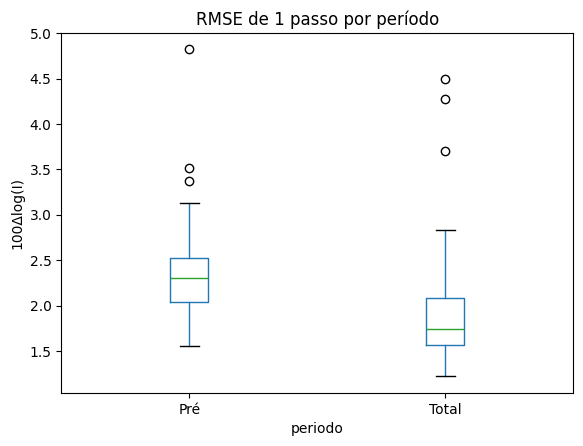

In [4]:
refs.boxplot(column="RMSE",by="periodo",grid=False);plt.suptitle("");plt.title("RMSE de 1 passo por período");plt.ylabel("100Δlog(I)");plt.show()

## 4. Interpretação

Um SARIMA de menor BIC pode falhar no diagnóstico residual; tais casos não são promovidos a modelos plenamente adequados. O RMSE é da variável transformada `100Δlog(I)`, não pontos percentuais da taxa em nível.